# Assignment 2

## Extract data from the json file

Write a script, that would extract all the the data from the json file and return it in a list of texts for further use in the next tasks

In [1]:
import json

def extract_texts_from_file(file_path):
    """
    Extract the text data from the json file

    Args:
        file_path (str): Relative location of the json file in the project.

    Returns:
        list: The list of texts as strings.
    """
    with open(file_path, "r", encoding="utf-8") as f:
        data = json.load(f)
    return data["texts"]

texts = extract_texts_from_file('resources/data.json')
print(texts)

['Oppenheimer, directed by Christopher Nolan, delves into the life of J. Robert Oppenheimer, the theoretical physicist who led the development of the atomic bomb. The film explores his moral and emotional struggles.', "Oppenheimer captures the life of the 'father of the atomic bomb' and his internal conflict after the success of the Manhattan Project. The film's complex narrative reflects on the cost of scientific achievement.", 'In Oppenheimer, Cillian Murphy delivers a riveting performance as the conflicted physicist who grapples with the consequences of his groundbreaking work on the atomic bomb, under the weight of global politics and ethics.', 'Oppenheimer is a cinematic exploration of ambition, guilt, and responsibility. Through stunning visuals and a thought-provoking story, Nolan brings the life of the brilliant but haunted physicist to the big screen.', 'Ducks are versatile waterfowl, known for their adaptability in freshwater and coastal habitats. With webbed feet and waterpr

## Process the texts

Write a script, that would process these texts. Processing should include:

- Lowercasing
- Removing Punctuation
- Removing Special Characters and Numbers
- Stemming or Lemmatization
- Handling Abbreviations
- Spelling Correction

In [12]:
!pip install sentence-transformers


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# pip install nltk contractions pyspellchecker
import re
import nltk
import contractions
from nltk.corpus import wordnet
from nltk.stem import WordNetLemmatizer
from spellchecker import SpellChecker

for pkg in ("wordnet", "omw-1.4", "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"):
    nltk.download(pkg, quiet=True)

# Abbreviations that contractions.fix() doesn't cover. Extend as needed.
ABBREVIATIONS = {
    "dr": "doctor", "mr": "mister", "mrs": "missus", "prof": "professor",
    "govt": "government", "approx": "approximately", "info": "information",
    "vs": "versus", "etc": "et cetera", "eg": "for example", "ie": "that is",
}

# Domain words and proper nouns the spell checker must not "correct".
PROTECTED_WORDS = [
    "oppenheimer", "nolan", "cillian", "murphy", "manhattan",
    "dijkstra", "kruskal", "waterfowl", "waterproof",
]

_lemmatizer = WordNetLemmatizer()
_spell = SpellChecker()
_spell.word_frequency.load_words(PROTECTED_WORDS)


def _wordnet_pos(tag):
    return {"J": wordnet.ADJ, "V": wordnet.VERB, "R": wordnet.ADV}.get(tag[0], wordnet.NOUN)


def _process_one(text):
    # 1. Lowercase and normalise curly apostrophes
    text = text.lower().replace("’", "'").replace("‘", "'")

    # 2. Handle contractions ("it's" -> "it is"), then drop possessives ("dijkstra's" -> "dijkstra")
    text = contractions.fix(text)
    text = re.sub(r"\b(\w+)'s\b", r"\1", text)

    # 3. Remove punctuation, special characters and numbers
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = text.split()

    # 4. Expand abbreviations
    expanded = []
    for tok in tokens:
        expanded.extend(ABBREVIATIONS.get(tok, tok).split())

    # 5. Spelling correction (only for words the dictionary doesn't know)
    unknown = _spell.unknown(expanded)
    corrected = [
        (_spell.correction(t) or t) if t in unknown else t
        for t in expanded
    ]

    # 6. Lemmatization, using POS tags for better results
    tagged = nltk.pos_tag(corrected)
    lemmas = [_lemmatizer.lemmatize(w, _wordnet_pos(tag)) for w, tag in tagged]

    return " ".join(lemmas)


def process_texts(texts):
    """
    Process the texts

    Args:
        texts (list): list of str texts to be processed.

    Returns:
        list: The list of texts as strings processed by script.
    """
    return [_process_one(t) for t in texts]


texts_processed = process_texts(texts)
print(texts_processed)

['oppenheimer direct by christopher nolan delve into the life of j robert oppenheimer the theoretical physicist who lead the development of the atomic bomb the film explore his moral and emotional struggle', 'oppenheimer capture the life of the father of the atomic bomb and his internal conflict after the success of the manhattan project the film complex narrative reflect on the cost of scientific achievement', 'in oppenheimer cillian murphy delivers a riveting performance a the conflicted physicist who grapple with the consequence of his groundbreaking work on the atomic bomb under the weight of global politics and ethic', 'oppenheimer be a cinematic exploration of ambition guilt and responsibility through stunning visuals and a thought provoke story nolan bring the life of the brilliant but haunt physicist to the big screen', 'duck be versatile waterfowl know for their adaptability in freshwater and coastal habitat with webbed foot and waterproof feather they be excellent swimmer mig

## Calculate cosine similarities using TFIDF

Calculate the TFIDF score and cosine similarity between the texts. You may use gensim, write your own script using numpy or use other module. Output the result as a matrix $n\times n$  of cosine similarity scores (where $n$ is the length of texts list).

Extra credit: use word2vec word embeddings in vector spaces to get better TFIDF scores by representing each word as a vector.

In [6]:
# pip install scikit-learn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

def calcuate_tfidf(texts_processed):
    """
    Calculate TFIDF score between the texts in the list.

    Args:
        texts_processed (list): list of texts, processed in previous task.

    Returns:
        cosine_matrix (list): a matrix of cosine similarity scores.
    """
    vectorizer = TfidfVectorizer()
    tfidf_matrix = vectorizer.fit_transform(texts_processed)   # shape: (n_texts, n_terms)
    cosine_matrix = cosine_similarity(tfidf_matrix)             # shape: (n_texts, n_texts)
    return cosine_matrix.tolist()

cosine_matrix = calcuate_tfidf(texts_processed)
print(cosine_matrix)

[[1.0000000000000004, 0.43097755553025585, 0.3414405604226896, 0.27603780045475057, 0.015827180984303225, 0.06413956852656495, 0.09292720161912717, 0.04309937311532061, 0.03949772167306397, 0.08140415714691773], [0.43097755553025585, 0.9999999999999998, 0.36180252750424635, 0.2647261596689047, 0.014261631945455499, 0.07913454689724575, 0.13893748325472915, 0.050486328406472755, 0.04779292506857154, 0.12484277568964267], [0.3414405604226896, 0.36180252750424635, 1.0000000000000002, 0.18764886920299945, 0.056029692319080684, 0.053432240466720245, 0.11237258838530693, 0.0490353703363132, 0.05774898442862045, 0.08806530926560673], [0.27603780045475057, 0.2647261596689047, 0.18764886920299945, 1.0000000000000009, 0.07903230962472571, 0.12433342693793391, 0.10775088660858578, 0.08485756831875219, 0.06967192570608151, 0.07774467978443085], [0.015827180984303225, 0.014261631945455499, 0.056029692319080684, 0.07903230962472571, 1.0000000000000002, 0.07391985225056762, 0.15220517183117954, 0.064

## Visualize data

Visualize the cosine_matrix data using matplotlib. Choose your own method of plotting the scores in a way, that the similarity indeces between texts would be instantly visible. Plot data about texts as well (a couple of first words in the document).

*Hint: remember heat maps, aren't they nice for this task?*

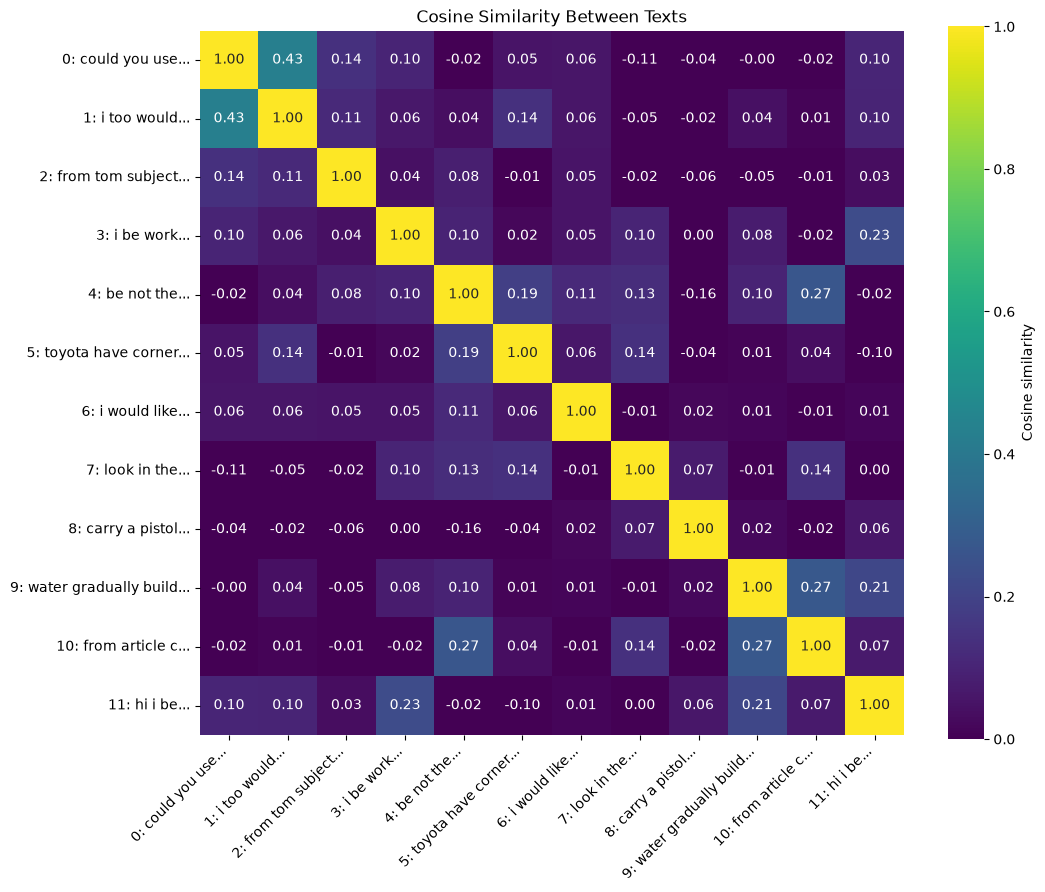

In [16]:
# pip install matplotlib seaborn numpy
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def visualize_data(cosine_matrix, texts_processed):
    """
    Visualize the cosine similarity matrix from the previous task.

    Args:
        cosine_matrix (list): matrix of cosine similarity scores (values from 0.0 to 1.0 expected).
        texts_processed (list): list of texts, processed in previous task.

    Returns:
        None: None.
    """
    matrix = np.array(cosine_matrix)

    # Short axis labels: index plus the first three words of each text
    labels = [f"{i}: {' '.join(t.split()[:3])}..." for i, t in enumerate(texts_processed)]

    plt.figure(figsize=(11, 9))
    sns.heatmap(
        matrix,
        annot=True,
        fmt=".2f",
        cmap="viridis",
        vmin=0.0,
        vmax=1.0,
        square=True,
        xticklabels=labels,
        yticklabels=labels,
        cbar_kws={"label": "Cosine similarity"},
    )
    plt.title("Cosine Similarity Between Texts")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

visualize_data(cosine_matrix, texts_processed)

## Analyse your own text using TFIDF (or any other method)

Analyse your own text using previous methods. You may use API fetching to get text data, download texts from Kaggle or use any texts you want. Find cosine similarities and visualize them

Recommendation: use sentence_transform / openai embedding model

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2471.64it/s]


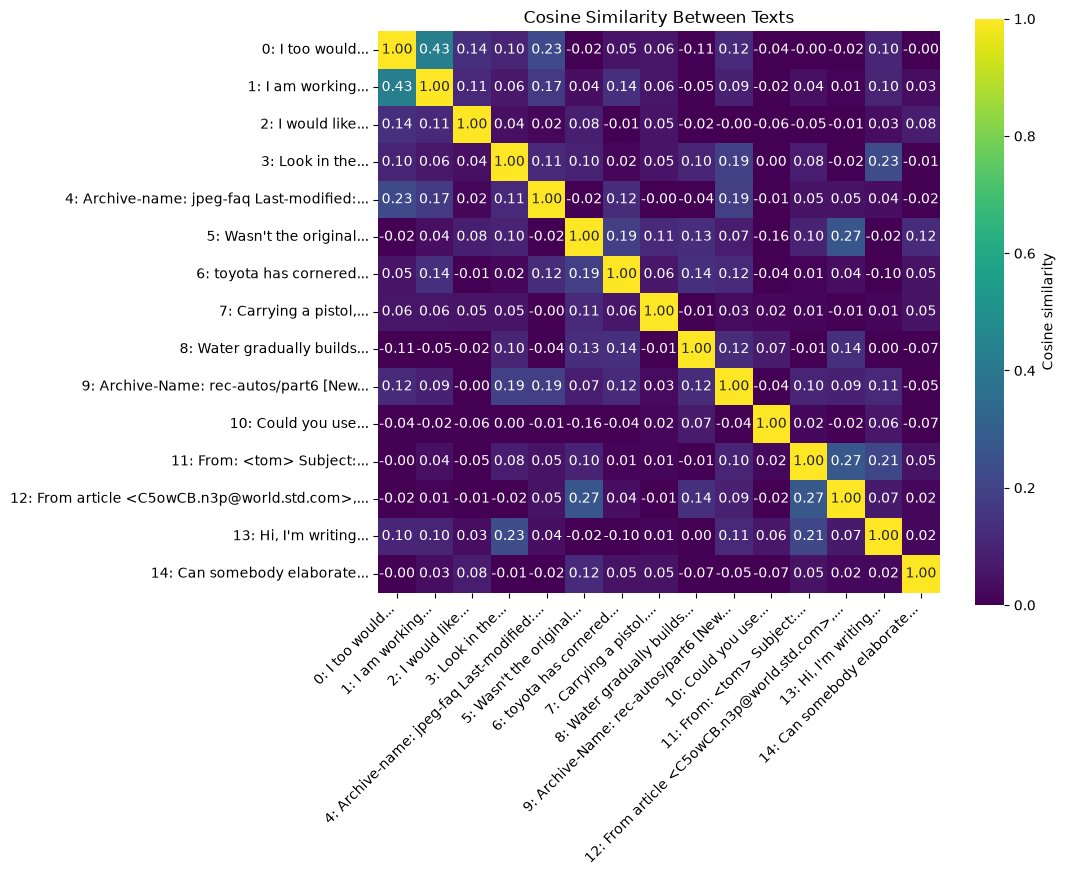

In [18]:
from sklearn.datasets import fetch_20newsgroups
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

def get_texts():
    categories = ["sci.space", "rec.autos", "comp.graphics"]
    data = fetch_20newsgroups(
        subset="train",
        categories=categories,
        remove=("headers", "footers", "quotes"),
    )

    per_category = {c: [] for c in range(len(categories))}
    for text, label in zip(data.data, data.target):
        text = text.strip()
        if len(text) < 200:                      # skip near-empty posts
            continue
        if len(per_category[label]) < 5:         # 4 texts per category -> 12 total
            per_category[label].append(text)
        if all(len(v) == 4 for v in per_category.values()):
            break

    # concatenate category by category so similar texts sit next to each other
    return [t for label in sorted(per_category) for t in per_category[label]]


def calcuate_embeddings_similarity(texts):
    model = SentenceTransformer("all-MiniLM-L6-v2")   # ~80 MB, downloaded on first run
    embeddings = model.encode(texts)                  # shape: (n_texts, 384)
    return cosine_similarity(embeddings).tolist()


texts = get_texts()
cosine_matrix = calcuate_embeddings_similarity(texts)
visualize_data(cosine_matrix, texts)   # raw texts are used only for the axis labels